# M2 Assignment Solution
**Kapil Kumar Sharma**

**NET ID: apl25002**

**Date: 14-09-2026**


# Initialization and mounting to drive

In [205]:
# import modules

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set display options to show all columns
pd.set_option('display.max_columns', None)

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Task 1: Read in the dataset and determine how many rows and columns it has.

* First we read the csv 'Telco_customer_churn.csv' file.
* Then print the shape of the data frame, that shows number of rows and columns in dataset.

In [206]:
#from google.colab import drive
#df = pd.read_csv('/content/drive/MyDrive/spotify-2023.csv')

#Error:UnicodeDecodeError: 'utf-8' codec can't decode bytes in position 7917-7918: invalid continuation byte

Error is due to the encoding type of the file. To solve this issue, I have open the file in notepad and then 'SaveAs' txt file, with encoding 'UTF8'.
Uploaded the new txt file to drive and then retry to read the file.

In [207]:
from google.colab import drive
df = pd.read_csv('/content/drive/MyDrive/spotify-2023.txt')
df.shape

(953, 25)

# Task 2: The target variable for this dataset is the streams column. It is shown two ways - "streams" is the full number and "streams (M)" is the the number in millions.  Check the datatype of streams (M). If it isn’t already float64, update it. Hint: if needed, drop a row of problematic data to get it to convert properly.

* Checking the datatype of streams (M).


In [208]:
# Verify the datatype of 'streams (M)
print("Datatype of stream [M] is:  ", df['streams (M)'].dtypes)

df['streams (M)'].head(5)

Datatype of stream [M] is:   object


,streams (M)
0,141.381703
1,133.716286
2,140.003974
3,800.840817
4,303.236322


* Datatype of 'steam [M]' variable is object, changing it to float64

In [209]:
# Change 'streams (M)' from object to float64
#df['streams (M)'] = pd.to_numeric(df['streams (M)'])

#Error on runing above code:
#ValueError: Unable to parse string "BPM110KeyAModeMajorDanceability53Valence75Energy69Acousticness7Instrumentalness0Liveness17Speechiness3" at position 574


Comment: So there is a string value at position 574 and it seems data is incorrect. We have two option now:
1. Omission
2. Imputation


We will go with Omission as the data having the issue is just one row and we have sufficient data for our task.

In [210]:
display(df.loc[[574]])

,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,streams (M),in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
574,Love Grows (Where My Rosemary Goes),Edison Lighthouse,1,1970,1,1,2877,0,BPM110KeyAModeMajorDanceability53Valence75Ener...,BPM110KeyAModeMajorDanceability53Valence75Ener...,16,0,54,0,0,110,A,Major,53,75,69,7,0,17,3


In [211]:
df = df.drop(574)

In [212]:
# Change 'streams (M)' from object to float64
df['streams (M)'] = pd.to_numeric(df['streams (M)'])

# Verify the datatype change
print(df['streams (M)'].dtypes)

# Display the head of the 'Mfg_Month' column to see the change
print(df['streams (M)'].head())

float64
0    141.381703
1    133.716286
2    140.003974
3    800.840817
4    303.236322
Name: streams (M), dtype: float64


Comment: After dropping the problematic row/data, conversion from object to float for variable 'streams (M)' is successful.

# Task 3: Check the remaining variables. Do any other columns need their data type updated?
* Checking the data of int/float
* Then for 'object'

Will action for conversion, if required after review data head and type.


In [213]:
temp_df = df.select_dtypes(include=["int64", "float64"])
print(temp_df.head())

   artist_count  released_year  released_month  released_day  \
0             2           2023               7            14   
1             1           2023               3            23   
2             1           2023               6            30   
3             1           2019               8            23   
4             1           2023               5            18   

   in_spotify_playlists  in_spotify_charts  streams (M)  in_apple_playlists  \
0                   553                147   141.381703                  43   
1                  1474                 48   133.716286                  48   
2                  1397                113   140.003974                  94   
3                  7858                100   800.840817                 116   
4                  3133                 50   303.236322                  84   

   in_apple_charts  in_deezer_charts  bpm  danceability_%  valence_%  \
0              263                10  125              80         89

In [214]:
temp_df = df.select_dtypes(include=["object"])
print(temp_df.head())

                            track_name    artist(s)_name    streams  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook  141381703   
1                                 LALA       Myke Towers  133716286   
2                              vampire    Olivia Rodrigo  140003974   
3                         Cruel Summer      Taylor Swift  800840817   
4                       WHERE SHE GOES         Bad Bunny  303236322   

  in_deezer_playlists in_shazam_charts key   mode  
0                  45              826   B  Major  
1                  58              382  C#  Major  
2                  91              949   F  Major  
3                 125              548   A  Major  
4                  87              425   A  Minor  


* Variable 'in_deezer_playlists' and 'in_shazam_charts' is more continuous type.

First let's update the datatype 'in_deezer_playlists' from object to number.

In [215]:
# Change 'in_deezer_playlists' from object to int64
#df['in_deezer_playlists'] = pd.to_numeric(df['in_deezer_playlists'])

#Error in above code:
#ValueError: Unable to parse string "2,445"

Comment: We are getting parsing error due to ',' in numeric value. We are going fix it.

In [216]:
display(df.loc[[48]])

,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,streams (M),in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
48,Starboy,"The Weeknd, Daft Punk",2,2016,9,21,29536,79,2565529693,2565.529693,281,137,"2,445",1,140,186,G,Major,68,49,59,16,0,13,28


From the data, it seems most of the value have ',' in it. So lets fix the ',' and then will convert to number.

* lets count the number of rows with ',' in it
* Then remove the ',' from all, so that it can be changed to int64
* Then change the datatype to int64

In [217]:
count = df['in_deezer_playlists'].str.contains(',', na=False).sum()
print("Total number of values with ',' in it: ", count)

df.shape

Total number of values with ',' in it:  79


(952, 25)

In [218]:
i = 0
for i, colValue in df['in_deezer_playlists'].items():
    if ',' in str(colValue):
        df.loc[i, 'in_deezer_playlists'] = str(colValue).replace(',', '')
        print("Row:", i, "and Value is:", colValue, " is now updated to: ", df.loc[i, 'in_deezer_playlists'])

Row: 48 and Value is: 2,445  is now updated to:  2445
Row: 54 and Value is: 3,394  is now updated to:  3394
Row: 55 and Value is: 3,421  is now updated to:  3421
Row: 65 and Value is: 4,053  is now updated to:  4053
Row: 73 and Value is: 1,056  is now updated to:  1056
Row: 75 and Value is: 4,095  is now updated to:  4095
Row: 80 and Value is: 1,003  is now updated to:  1003
Row: 86 and Value is: 1,800  is now updated to:  1800
Row: 88 and Value is: 2,703  is now updated to:  2703
Row: 98 and Value is: 1,632  is now updated to:  1632
Row: 103 and Value is: 2,394  is now updated to:  2394
Row: 106 and Value is: 1,034  is now updated to:  1034
Row: 109 and Value is: 2,163  is now updated to:  2163
Row: 114 and Value is: 2,655  is now updated to:  2655
Row: 126 and Value is: 6,551  is now updated to:  6551
Row: 127 and Value is: 1,212  is now updated to:  1212
Row: 128 and Value is: 1,078  is now updated to:  1078
Row: 138 and Value is: 2,094  is now updated to:  2094
Row: 140 and Value i

In [219]:
# Change 'in_deezer_playlists' from object to float64
df['in_deezer_playlists'] = pd.to_numeric(df['in_deezer_playlists'])

# Verify the datatype change
print(df['in_deezer_playlists'].dtypes)

# Display the head of the 'Mfg_Month' column to see the change
print(df['in_deezer_playlists'].head())

int64
0     45
1     58
2     91
3    125
4     87
Name: in_deezer_playlists, dtype: int64


So we are done with the column 'in_deezer_playlists'.

Now let's update the datatype 'in_shazam_charts' from object to number. Following the similar steps.

In [220]:
count = df['in_shazam_charts'].str.contains(',', na=False).sum()
print("Total number of values with ',' in it: ", count)

df.shape

Total number of values with ',' in it:  7


(952, 25)

In [221]:
i = 0
for i, colValue in df['in_shazam_charts'].items():
    if ',' in str(colValue):
        print("Row:", i, "and Value is:", colValue)
        df.loc[i, 'in_shazam_charts'] = str(colValue).replace(',', '')
        print("Comma removed successfuly!...")

Row: 12 and Value is: 1,021
Comma removed successfuly!...
Row: 13 and Value is: 1,281
Comma removed successfuly!...
Row: 17 and Value is: 1,173
Comma removed successfuly!...
Row: 24 and Value is: 1,093
Comma removed successfuly!...
Row: 44 and Value is: 1,133
Comma removed successfuly!...
Row: 88 and Value is: 1,451
Comma removed successfuly!...
Row: 89 and Value is: 1,170
Comma removed successfuly!...


In [222]:
# Change 'in_shazam_charts' from object to float64
df['in_shazam_charts'] = pd.to_numeric(df['in_shazam_charts'])

# Verify the datatype change
print(df['in_shazam_charts'].dtypes)

# Display the head of the 'Mfg_Month' column to see the change
print(df['in_shazam_charts'].head())

float64
0    826.0
1    382.0
2    949.0
3    548.0
4    425.0
Name: in_shazam_charts, dtype: float64


In [223]:
print(df[df['in_shazam_charts'].isna()].index)

Index([ 14,  54,  55,  71,  73,  86, 127, 158, 159, 180, 243, 274, 320, 392,
       395, 403, 410, 429, 434, 440, 441, 442, 443, 444, 446, 449, 500, 501,
       504, 506, 507, 513, 518, 519, 520, 529, 531, 532, 533, 534, 535, 549,
       554, 560, 566, 584, 620, 625, 727, 927],
      dtype='int64')


* Replacing 'nan' with real missing value (NaN)
* We should not replace 'nan' string with 0 because missing does not necessarily mean zero.
* We have to handle the missing value by 'imputation', may be by replacing all missing value with the median.

In [224]:
df['in_shazam_charts'] = df['in_shazam_charts'].replace('nan', np.nan)
df['in_shazam_charts'] = pd.to_numeric(df['in_shazam_charts'], errors='coerce')

Comment: We were able to update data type for 'in_deezer_playlists' after removing comma ',' from few of it's data. For 'in_shazam_charts', we have to replace 'nan' with missing value and change it number.

In [225]:
temp_df = df.select_dtypes(include=["int64", "float64"])
print(temp_df.head())

   artist_count  released_year  released_month  released_day  \
0             2           2023               7            14   
1             1           2023               3            23   
2             1           2023               6            30   
3             1           2019               8            23   
4             1           2023               5            18   

   in_spotify_playlists  in_spotify_charts  streams (M)  in_apple_playlists  \
0                   553                147   141.381703                  43   
1                  1474                 48   133.716286                  48   
2                  1397                113   140.003974                  94   
3                  7858                100   800.840817                 116   
4                  3133                 50   303.236322                  84   

   in_apple_charts  in_deezer_playlists  in_deezer_charts  in_shazam_charts  \
0              263                   45                10    

In [226]:
temp_df = df.select_dtypes(include=["object"])
print(temp_df.head())

                            track_name    artist(s)_name    streams key   mode
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook  141381703   B  Major
1                                 LALA       Myke Towers  133716286  C#  Major
2                              vampire    Olivia Rodrigo  140003974   F  Major
3                         Cruel Summer      Taylor Swift  800840817   A  Major
4                       WHERE SHE GOES         Bad Bunny  303236322   A  Minor


Comment: Data type of all columns look fine now.

# Task 4: Practice binning in_spotify_playlists. Show a histogram of the bins you made.


* For variable 'in_spotify_playlists'

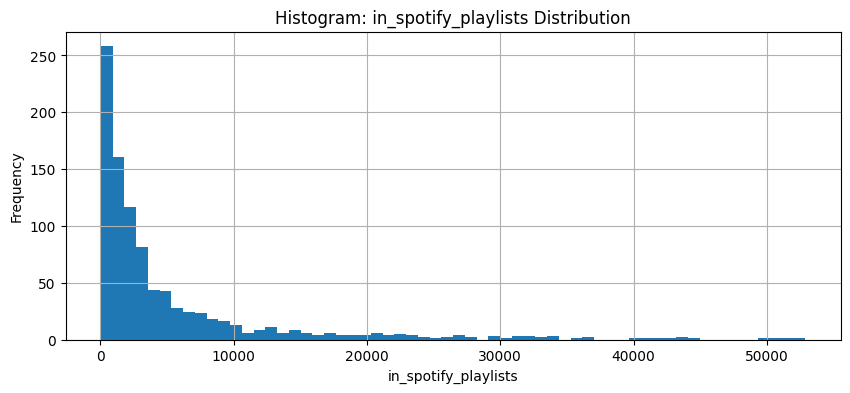

In [227]:
# Histogram of in_spotify_playlists
plt.figure(figsize=(10,4))
df['in_spotify_playlists'].hist(bins=60)
plt.title('Histogram: in_spotify_playlists Distribution')
plt.xlabel('in_spotify_playlists')
plt.ylabel('Frequency') # Added y-axis label for clarity
plt.show()

In [228]:
df['in_spotify_playlists'].describe()


,in_spotify_playlists
count,952.000000
mean,5202.565126
std,7901.400683
min,31.000000
25%,874.500000
50%,2216.500000
75%,5573.750000
max,52898.000000


* Since the variable ranges from 31 to 52,898 and is strongly right-skewed (mean 5,177 vs. median 2,209), creating unequal-width bins to better represent the distribution.

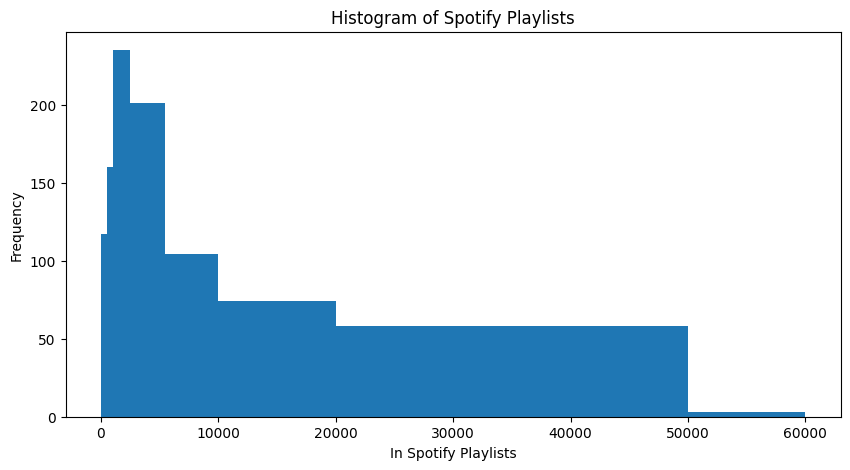

In [229]:
plt.figure(figsize=(10, 5))

plt.hist(
    df['in_spotify_playlists'],
    bins=[0, 500, 1000, 2500, 5500, 10000, 20000, 50000, 60000]
)

plt.xlabel('In Spotify Playlists')
plt.ylabel('Frequency')
plt.title('Histogram of Spotify Playlists')
plt.show()

In [230]:
bins = [0, 500, 1000, 2500, 5500, 10000, 20000, 50000, 60000]

labels = [
    '0-500',
    '501-1000',
    '1001-2500',
    '2501-5500',
    '5501-10000',
    '10001-20000',
    '20001-50000',
    '50001-60000'
]

df['spotify_playlist_bin'] = pd.cut(
    df['in_spotify_playlists'],
    bins=bins,
    labels=labels
)

In [231]:
df['spotify_playlist_bin'].head(15)

,spotify_playlist_bin
0,501-1000
1,1001-2500
2,1001-2500
3,5501-10000
4,2501-5500
5,1001-2500
6,2501-5500
7,501-1000
8,1001-2500
9,2501-5500


# Task 5. Find the missing values in the dataset and handle them appropriately. Which column(s) had the most missing values?

* Creating nested loop. The top loop will traverse thru all column and inner loop will traverse through all value for a particular column.
* First we will print the missing value count for each column.
* Adding on extra counter which will keep indicator for the maximum count value and variable name in it.

In [232]:
maxVar = ""
maxCount = 0

for col in df.columns:
    count = 0
    for value in df[col]:
        if pd.isna(value):
            count += 1
    print("Column name : ", col, " , missing value count :", count)
    if(count > maxCount):
        maxCount = count
        maxVar = col

#both loop ends.
print("Column with most/maximum missing values is: ", maxVar, " And the total count of missing values in it is: ", maxCount)

Column name :  track_name  , missing value count : 0
Column name :  artist(s)_name  , missing value count : 0
Column name :  artist_count  , missing value count : 0
Column name :  released_year  , missing value count : 0
Column name :  released_month  , missing value count : 0
Column name :  released_day  , missing value count : 0
Column name :  in_spotify_playlists  , missing value count : 0
Column name :  in_spotify_charts  , missing value count : 0
Column name :  streams  , missing value count : 0
Column name :  streams (M)  , missing value count : 0
Column name :  in_apple_playlists  , missing value count : 0
Column name :  in_apple_charts  , missing value count : 0
Column name :  in_deezer_playlists  , missing value count : 0
Column name :  in_deezer_charts  , missing value count : 0
Column name :  in_shazam_charts  , missing value count : 50
Column name :  bpm  , missing value count : 0
Column name :  key  , missing value count : 95
Column name :  mode  , missing value count : 0


Handling missing value for column 'key' and 'in_shazam_charts'

In [233]:
df['key'].unique()

count_nan = df['key'].isna().sum()
print("Number of NaN values:", count_nan)

Number of NaN values: 95


For 'key', we will use "Unknown" to fill all the nan rows as imputation value.

In [234]:
df['key'] = df['key'].fillna('Unknown')

In [235]:
print(df['key'].value_counts())

key
C#         120
G           96
Unknown     95
G#          91
F           89
B           81
D           81
A           74
F#          73
E           62
A#          57
D#          33
Name: count, dtype: int64


For 'in_shazam_charts' with just 50 values missing, we could drop the rows. But let's use imputation so you can see how it works. In this case we are imputing with the column mean.

In [236]:
# Update the missing values in the in_shazam_charts column using imputation
mean_isc = df['in_shazam_charts'].mean() # Calculate the mean
print(f"Imputing missing in_shazam_charts values with the mean: {mean_isc:.2f}") # Print the mean used
df['in_shazam_charts'].fillna(mean_isc, inplace=True)

# Verify that the missing values in 'in_shazam_charts' have been filled
print("\nMissing values after filling missing in_shazam_charts:")
print(df.isnull().sum())

Imputing missing in_shazam_charts values with the mean: 60.06

Missing values after filling missing in_shazam_charts:
track_name              0
artist(s)_name          0
artist_count            0
released_year           0
released_month          0
released_day            0
in_spotify_playlists    0
in_spotify_charts       0
streams                 0
streams (M)             0
in_apple_playlists      0
in_apple_charts         0
in_deezer_playlists     0
in_deezer_charts        0
in_shazam_charts        0
bpm                     0
key                     0
mode                    0
danceability_%          0
valence_%               0
energy_%                0
acousticness_%          0
instrumentalness_%      0
liveness_%              0
speechiness_%           0
spotify_playlist_bin    0
dtype: int64


/tmp/ipykernel_3244/3994000358.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['in_shazam_charts'].fillna(mean_isc, inplace=True)


#Task 6: Find the potential outliers in the dataset and handle them appropriately. What artist(s) are associated with the most extreme outliers?

* For potential outliers, in the complete dataset, we will evaluate IQR for each variable and count the potential outlier for each column.
* By column, we mean continuous (number) variables only.
* We will be following IQR method to evaluate potential outlier.
* IQR = Q3 - Q1
* Potential Outlier = if column value is < Q1 - 1.5XIQR OR value is > Q3 + 1.5 X IQR

In [237]:
for col in df.select_dtypes(include='number').columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = 0

    for value in df[col]:
        if value < lower or value > upper:
            count += 1

    print(col, ":", count, "potential outliers")

artist_count : 27 potential outliers
released_year : 150 potential outliers
released_month : 0 potential outliers
released_day : 0 potential outliers
in_spotify_playlists : 109 potential outliers
in_spotify_charts : 78 potential outliers
streams (M) : 74 potential outliers
in_apple_playlists : 78 potential outliers
in_apple_charts : 9 potential outliers
in_deezer_playlists : 154 potential outliers
in_deezer_charts : 143 potential outliers
in_shazam_charts : 113 potential outliers
bpm : 5 potential outliers
danceability_% : 3 potential outliers
valence_% : 0 potential outliers
energy_% : 4 potential outliers
acousticness_% : 0 potential outliers
instrumentalness_% : 87 potential outliers
liveness_% : 44 potential outliers
speechiness_% : 136 potential outliers


* Regarding what artist(s) are associated with the most extreme outliers?
* We have to evaluate extreme outliers
* Calculate outlier distance and corresponding index by applying lambda function
* We are able to list the artist(s) associated with the most extreme outliers.


In [238]:
for col in df.select_dtypes(include='number').columns:
    #print(col)

    # Calculate the first and third quartiles (Q1 and Q3
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Find the most extreme value
    extreme = df[(df[col] < lower) | (df[col] > upper)].copy()

    if len(extreme) > 0:
        extreme['outlier_distance'] = extreme[col].apply(
            lambda x: max(lower - x, x - upper)
        )

        extreme = extreme.sort_values(
            'outlier_distance',
            ascending=False
        )

        print("\n", col)
        #print(extreme[['track_name', 'artist(s)_name', col, 'outlier_distance']].head(3))
        print(df.loc[extreme.index, ['artist(s)_name']])


 artist_count
                                        artist(s)_name
35   Big One, Duki, Lit Killah, Maria Becerra, FMK,...
642  Arcangel, De La Ghetto, Justin Quiles, Lenny T...
506  Adassa, Mauro Castillo, Stephanie Beatriz, Enc...
667  Quevedo, La Pantera, Juseph, Cruz Cafun  , B  ...
402  Vishal-Shekhar, Shilpa Rao, Caralisa Monteiro,...
393  Arijit Singh, Vishal Dadlani, Sukriti Kakar, V...
759  Jordan Fisher, Josh Levi, Finneas O'Connell, 4...
238     WizKid, Toian, Metro Boomin, Don Toliver, Beam
201    Kodak Black, NLE Choppa, Muni Long, JVKE, Jimin
328  Duki, NICKI NICOLE, Cris Mj, Standly, Stars Mu...
137  Sachin-Jigar, Shadab Faridi, Altamash Faridi, ...
864  De La Ghetto, Feid, Polima WestCoast, Paloma M...
365    Imagine Dragons, League of Legends, JID, Arcane
197                         Feid, Mora, Saiko, Quevedo
200          Swae Lee, Lil Wayne, Offset, Metro Boomin
135  Swae Lee, A Boogie Wit da Hoodie, Metro Boomin...
141       Veigh, Bvga Beatz, Supernova Ent, Prod M

# Task 7: Practice standardizing in_spotify_playlists.

* We will be using Standardizing function (Same as Z score)

In [239]:
df['in_spotify_playlists'].head(15)


,in_spotify_playlists
0,553
1,1474
2,1397
3,7858
4,3133
5,2186
6,3090
7,714
8,1096
9,2953


In [240]:
df['in_spotify_playlists'].describe()

,in_spotify_playlists
count,952.000000
mean,5202.565126
std,7901.400683
min,31.000000
25%,874.500000
50%,2216.500000
75%,5573.750000
max,52898.000000


Comment: From the above summary, 'in_spotify_playlists' is strongly righ-skewed.

z-score standardization:The formula is : z= (x−mean) / (standard deviation)
where x is df['in_spotify_playlists']

In [241]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df['in_spotify_playlists_standardized'] = scaler.fit_transform(
    df[['in_spotify_playlists']]
)

print(df[['in_spotify_playlists',
          'in_spotify_playlists_standardized']].head())

   in_spotify_playlists  in_spotify_playlists_standardized
0                   553                          -0.588758
1                  1474                          -0.472135
2                  1397                          -0.481885
3                  7858                           0.336248
4                  3133                          -0.262062


Comment: Standardization = subtract mean, divide by standard deviation → mean 0, std 1.

#Task 8: Practice transforming in_spotify_playlists. How does this differ from standardizing?

* First transform 'in_spotify_playlists'
* We already did standardization of 'in_spotify_playlists' to 'in_spotify_playlists_standardized'.

Transformation → change the scale/shape of the data, often to reduce skewness.

Standardization = subtract mean, divide by standard deviation → mean 0, std 1.

* Below two figure show histogram 'in_spotify_playlists' and 'in_spotify_playlists_standardized'

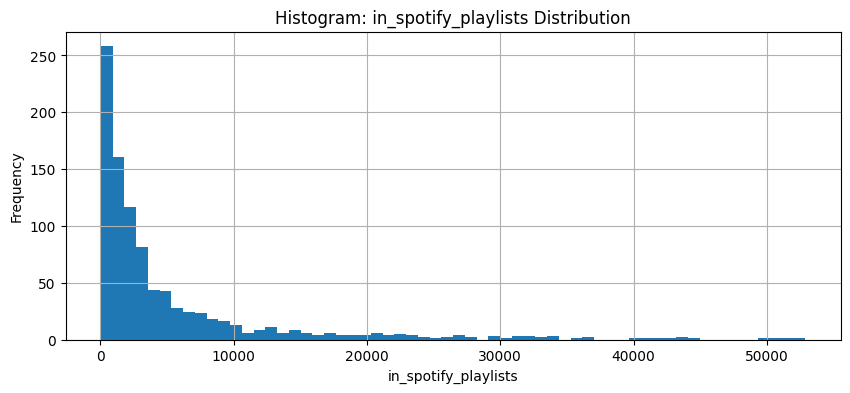

In [242]:
# Histogram of in_spotify_playlists
plt.figure(figsize=(10,4))
df['in_spotify_playlists'].hist(bins=60)
plt.title('Histogram: in_spotify_playlists Distribution')
plt.xlabel('in_spotify_playlists')
plt.ylabel('Frequency') # Added y-axis label for clarity
plt.show()

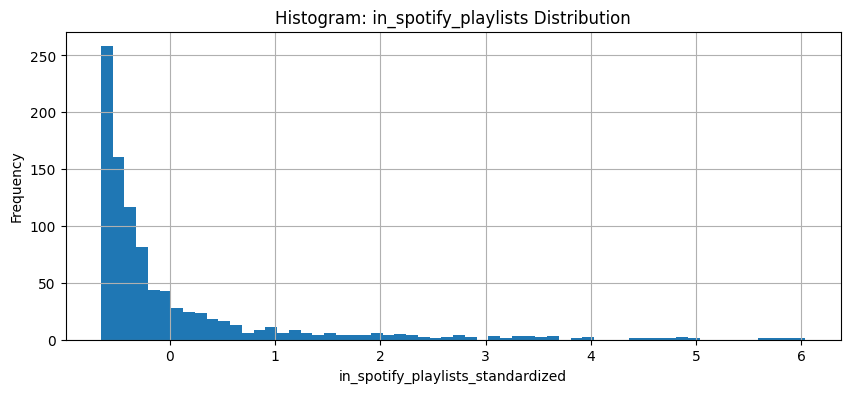

In [243]:
# Histogram of in_spotify_playlists
plt.figure(figsize=(10,4))
df['in_spotify_playlists_standardized'].hist(bins=60)
plt.title('Histogram: in_spotify_playlists Distribution')
plt.xlabel('in_spotify_playlists_standardized')
plt.ylabel('Frequency') # Added y-axis label for clarity
plt.show()

For Transformation: Lets plot histogram and boxplot for 'in_spotify_playlists' before transformation.

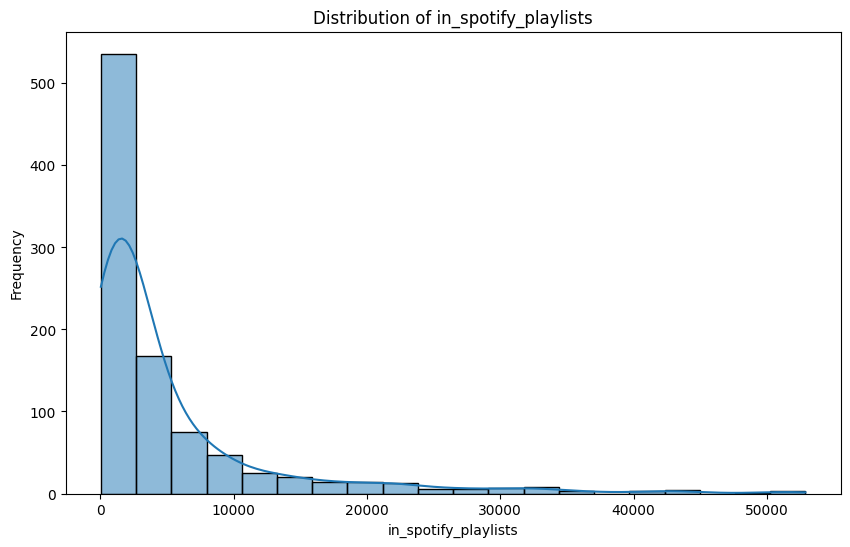

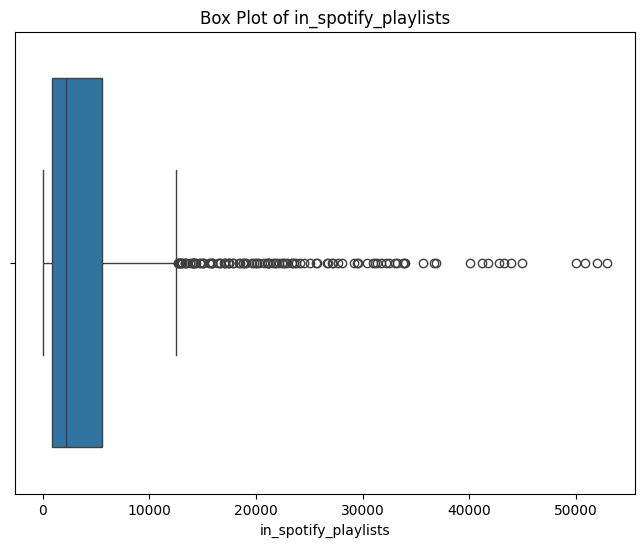

In [244]:
# Show a histogram of weight with box plot

plt.figure(figsize=(10, 6))

# Create the histogram
sns.histplot(data=df, x='in_spotify_playlists', bins=20, kde=True) # Added kde=True for density curve

plt.title('Distribution of in_spotify_playlists')
plt.xlabel('in_spotify_playlists')
plt.ylabel('Frequency')

plt.show()

# Create the box plot
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='in_spotify_playlists')
plt.title('Box Plot of in_spotify_playlists')
plt.xlabel('in_spotify_playlists')
plt.show()

Comment: There are many values that appear to be outliers. After applying the transformation, the shape of the distribution changes, reducing the impact of extreme values and making the distribution more balanced. However, the transformation does not necessarily remove the outliers completely.

   in_spotify_playlists  in_spotify_playlists_JohnsonSU
0                   553                       -1.053951
1                  1474                       -0.312466
2                  1397                       -0.352926
3                  7858                        0.942117
4                  3133                        0.254596


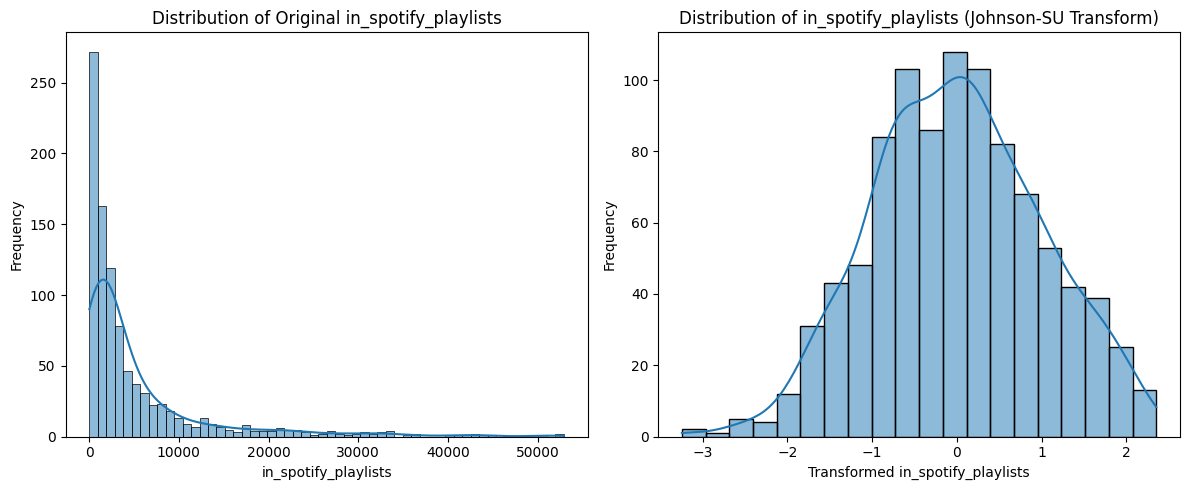

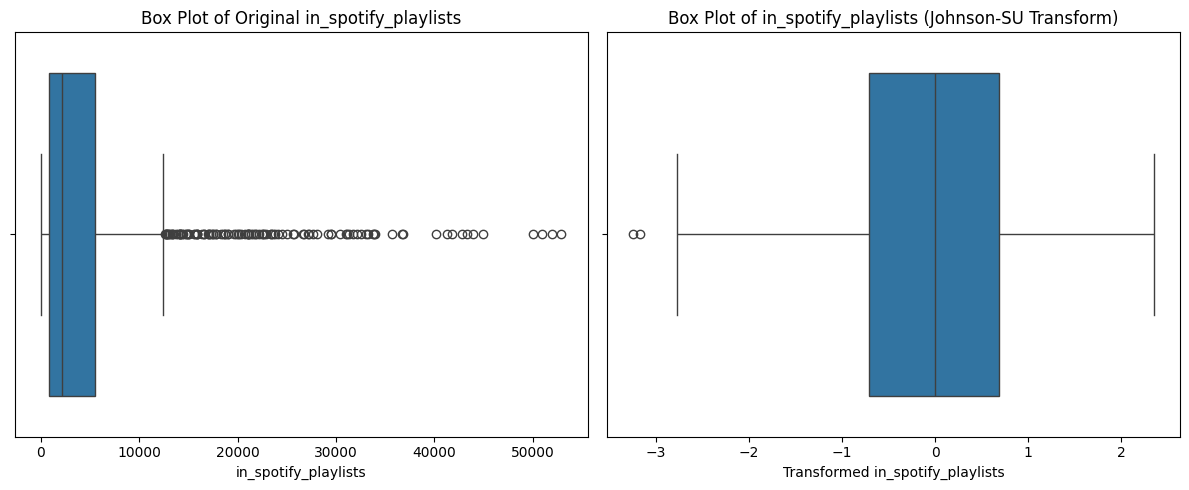

In [245]:
from sklearn.preprocessing import PowerTransformer

# Transform the in_spotify_playlists variable using the johnson su transform

# Initialize the PowerTransformer with the 'yeo-johnson' method
# The 'yeo-johnson' method can handle both positive and negative data
# For in_spotify_playlists, which is always positive, 'box-cox' would also be suitable.
# However, 'yeo-johnson' is more general and safer if other variables might have zeros or negatives.
pt = PowerTransformer(method='yeo-johnson', standardize=True) # standardize=True makes the transformed data zero mean, unit variance

# Reshape the data to be a 2D array (required by transform)
weight_reshaped = df['in_spotify_playlists'].values.reshape(-1, 1)

# Fit the transformer and transform the 'in_spotify_playlists' column
df['in_spotify_playlists_JohnsonSU'] = pt.fit_transform(weight_reshaped)

# Display the head with the original and transformed Weight columns
print(df[['in_spotify_playlists', 'in_spotify_playlists_JohnsonSU']].head())

# Lets visualize the distribution of the original and transformed Weight
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
sns.histplot(data=df, x='in_spotify_playlists', kde=True)
plt.title('Distribution of Original in_spotify_playlists')
plt.xlabel('in_spotify_playlists')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
sns.histplot(data=df, x='in_spotify_playlists_JohnsonSU', kde=True)
plt.title('Distribution of in_spotify_playlists (Johnson-SU Transform)')
plt.xlabel('Transformed in_spotify_playlists')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='in_spotify_playlists')
plt.title('Box Plot of Original in_spotify_playlists')
plt.xlabel('in_spotify_playlists')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='in_spotify_playlists_JohnsonSU')
plt.title('Box Plot of in_spotify_playlists (Johnson-SU Transform)')
plt.xlabel('Transformed in_spotify_playlists')

plt.tight_layout()
plt.show()

Comment: After transformation, for 'in_spotify_playlists' it changes both the scale and the shape of the distribution

# Task 9: Perform data reduction on the key variable. How many categories did you reduce it to?

* First analyize 'key' variable and
* Plan for data reduction

In [246]:
#df['key'].value_counts()

df['key'].unique()

array(['B', 'C#', 'F', 'A', 'D', 'F#', 'Unknown', 'G#', 'G', 'E', 'A#',
       'D#'], dtype=object)

In [ ]:
count_nan = df['key'].isna().sum()

print("Number of NaN / Missing values for 'key' variable is:", count_nan)

Number of NaN / Missing values for 'key' variable is: 0


When categorical variables are converted to dummy variables, they can make a dataset very wide with lots of columns. This increases the complexity of the dataspace because each new column is another dimension that the models need to account for.

To minimize this, we can combine categories that have similar behavior towards the target variable. In this case, let's look at how in_spotify_playlists impacts key.

In [247]:
# Make a table of key variable showing count, mean in_spotify_playlists, median in_spotify_playlists, standard deviation of in_spotify_playlists.
# sort ascending by mean in_spotify_playlists

# Group by 'key' and calculate the required statistics
spotify_key_summary = df.groupby('key')['in_spotify_playlists'].agg(['count', 'mean', 'median', 'std']).reset_index()

# Rename the columns for clarity
spotify_key_summary.columns = ['key', 'Count', 'Mean in_spotify_playlists', 'Median in_spotify_playlists', 'Std Dev in_spotify_playlists']

# Sort the table by 'Mean Price' in ascending order
spotify_key_summary_sorted = spotify_key_summary.sort_values(by='Mean in_spotify_playlists', ascending=True)

# Display the resulting table
print("Summary Table of in_spotify_playlists Statistics by key (Sorted by Mean in_spotify_playlists):")
spotify_key_summary_sorted

Summary Table of in_spotify_playlists Statistics by key (Sorted by Mean in_spotify_playlists):


,key,Count,Mean in_spotify_playlists,Median in_spotify_playlists,Std Dev in_spotify_playlists
0,A,74,3536.513514,1794.5,5267.754389
7,F,89,4479.146067,1622.0,6903.702402
10,G#,91,4575.769231,2114.0,6350.489402
2,B,81,4729.679012,1985.0,7209.295095
9,G,96,4966.500000,2080.0,7570.255800
1,A#,57,5061.333333,2795.0,6409.288520
6,E,62,5168.241935,2620.5,6325.350987
11,Unknown,95,5180.621053,1963.0,7546.135952
4,D,81,5625.641975,2616.0,8373.807310
8,F#,73,6026.657534,1634.0,10523.593017


* Group	Keys	Low, Medium, High
* Approx. (A, F, G#, B), (G, A#, E, D), (F#, D#, C#)
* Mean Range: (3,537–4,730), (4,967–5,626), (6,027–6,811)


Comment: We can reduce the key variable to 3 categories (Low, Medium, High) and for the nan values, we will use 'Unknown'

# Task 10: Practice making dummy variables for the new simplified key column. How many dummy variables did you make and why?

* specified the key maping as per the group defined above to make dummy variable.
* We can create three dummy variables—Low, Medium, and High—because these three variables cover all the known key categories. For a row where all three dummy variables are 0, we can interpret it as the Unknown category. This allows us to retain the Unknown data without creating a separate dummy variable for it.

In [248]:
key_mapping = {
    'A': 'Low',
    'F': 'Low',
    'G#': 'Low',
    'B': 'Low',
    'G': 'Medium',
    'A#': 'Medium',
    'E': 'Medium',
    'D': 'Medium',
    'F#': 'High',
    'D#': 'High',
    'C#': 'High'
}

df['key_reduced'] = df['key'].map(key_mapping).fillna('Unknown') # use fillna for nan type to mark it as 'Unknown'

In [249]:
# Verify the recoding by showing the first few rows with original and key_reduced
print("\nFirst few rows with original and recoded color:")
print(df[['key', 'key_reduced']].head())

df['key_low'] = (df['key_reduced'] == 'Low').astype(int)
df['key_medium'] = (df['key_reduced'] == 'Medium').astype(int)
df['key_high'] = (df['key_reduced'] == 'High').astype(int)



First few rows with original and recoded color:
  key key_reduced
0   B         Low
1  C#        High
2   F         Low
3   A         Low
4   A         Low


In [250]:
# Display the frequency of the new key reduced

print(df['key_reduced'].value_counts())

key_reduced
Low        335
Medium     296
High       226
Unknown     95
Name: count, dtype: int64


In [251]:
print(df[['key', 'key_reduced']].head())

  key key_reduced
0   B         Low
1  C#        High
2   F         Low
3   A         Low
4   A         Low


In [252]:
df.head()

,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,streams (M),in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%,spotify_playlist_bin,in_spotify_playlists_standardized,in_spotify_playlists_JohnsonSU,key_reduced,key_low,key_medium,key_high
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,141.381703,43,263,45,10,826.0,125,B,Major,80,89,83,31,0,8,4,501-1000,-0.588758,-1.053951,Low,1,0,0
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,133.716286,48,126,58,14,382.0,92,C#,Major,71,61,74,7,0,10,4,1001-2500,-0.472135,-0.312466,High,0,0,1
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,140.003974,94,207,91,14,949.0,138,F,Major,51,32,53,17,0,31,6,1001-2500,-0.481885,-0.352926,Low,1,0,0
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,800.840817,116,207,125,12,548.0,170,A,Major,55,58,72,11,0,11,15,5501-10000,0.336248,0.942117,Low,1,0,0
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,303.236322,84,133,87,15,425.0,144,A,Minor,65,23,80,14,63,11,6,2501-5500,-0.262062,0.254596,Low,1,0,0


Comment: We made 4 categories in the simplified key variable: Low, Medium, High, and Unknown. Normally, when creating dummy variables, we create 3 dummy variables for 4 categories to avoid the dummy variable trap (perfect multicollinearity).

#Task 11: Perform PCA on bpm, danceability_%, valence_%, energy_%, acousticness_%, instrumentalness_%, liveliness_%, and speechiness_%. How many principal components would you retain and why?

For PCA, first select the specified numeric variables, standardize them, and then apply PCA.

Correlation Matrix for PCA Variables:
                         bpm  danceability_%  valence_%  energy_%  \
bpm                 1.000000       -0.147630   0.041693  0.025932   
danceability_%     -0.147630        1.000000   0.409873  0.198485   
valence_%           0.041693        0.409873   1.000000  0.357516   
energy_%            0.025932        0.198485   0.357516  1.000000   
acousticness_%     -0.018065       -0.237128  -0.081161 -0.577318   
instrumentalness_% -0.001283       -0.089371  -0.132765 -0.038492   
liveness_%         -0.000803       -0.077665   0.021382  0.117334   
speechiness_%       0.038937        0.184393   0.041874 -0.004632   

                    acousticness_%  instrumentalness_%  liveness_%  \
bpm                      -0.018065           -0.001283   -0.000803   
danceability_%           -0.237128           -0.089371   -0.077665   
valence_%                -0.081161           -0.132765    0.021382   
energy_%                 -0.577318           -0.038492    0.

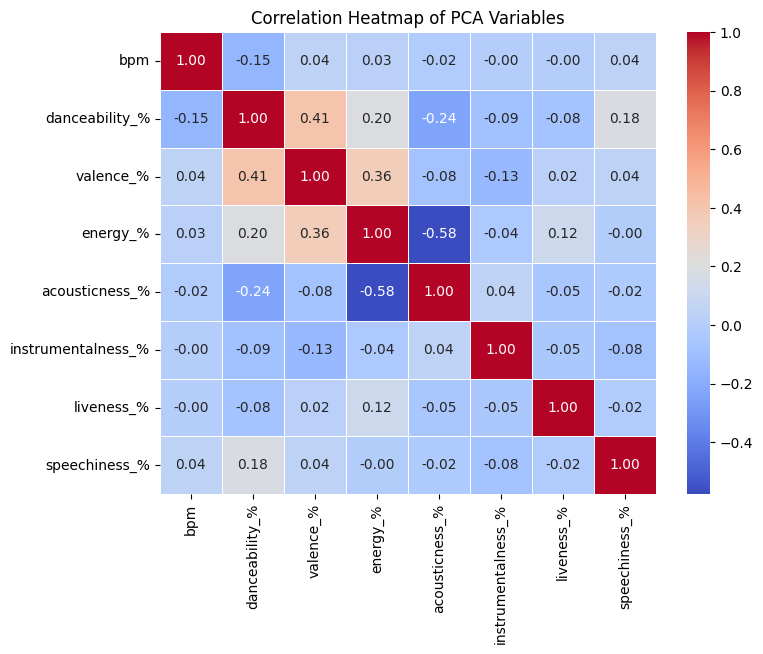

In [253]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select variables
pca_data = df[[
    'bpm',
    'danceability_%',
    'valence_%',
    'energy_%',
    'acousticness_%',
    'instrumentalness_%',
    'liveness_%',
    'speechiness_%'
]]

# Calculate the correlation matrix
correlation_matrix = pca_data.corr()

# Display the correlation matrix
print("Correlation Matrix for PCA Variables:")
print(correlation_matrix)

# Optionally visualize the correlation matrix with a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of PCA Variables')
plt.show()

Explained variance ratio by each principal component:
[0.24818126 0.15448278 0.13332236 0.12705087 0.11736538 0.10926731
 0.0716314  0.03869865]

Cumulative explained variance ratio:
[0.24818126 0.40266404 0.5359864  0.66303726 0.78040265 0.88966996
 0.96130135 1.        ]


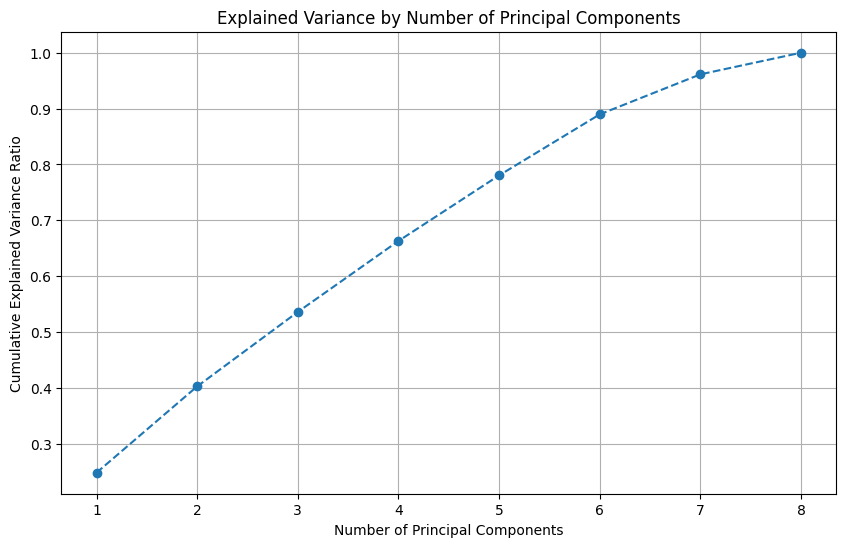


PCA Loadings (Component direction in original feature space):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
bpm,-0.020054,-0.228677,0.681793,-0.563068,-0.242076,0.085893,0.303580,0.085314
danceability_%,0.452938,0.445344,-0.206440,-0.009214,-0.026272,0.167011,0.658930,0.301732
valence_%,0.456434,0.238390,0.093828,0.030515,-0.544518,0.333320,-0.348472,-0.442797
energy_%,0.553660,-0.367468,-0.041456,-0.069008,0.024652,-0.052668,-0.413285,0.614623
acousticness_%,-0.483891,0.377029,0.117256,0.155251,-0.331657,0.312179,-0.235802,0.568148
instrumentalness_%,-0.158867,-0.259333,-0.490181,-0.444776,0.110743,0.673798,-0.017288,-0.053268
liveness_%,0.069381,-0.380029,0.319258,0.647946,0.176368,0.504768,0.206629,-0.020304
speechiness_%,0.123975,0.451317,0.355059,-0.188185,0.700168,0.211192,-0.287779,-0.042522


In [254]:
# Perform PCA on bpm, danceability_%, valence_%, energy_%, acousticness_%, instrumentalness_%, liveness_%, speechiness_%

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca_features = [
    'bpm',
    'danceability_%',
    'valence_%',
    'energy_%',
    'acousticness_%',
    'instrumentalness_%',
    'liveness_%',
    'speechiness_%'
]

# Define the features to use for PCA
df_pca = df[pca_features]

# Standardize the data before applying PCA
# PCA is affected by scale, so you need to scale features before applying it.
scaler = StandardScaler()
df_pca_scaled = scaler.fit_transform(df_pca)

# Apply PCA
# We will choose to keep all components for now to see the variance explained
pca = PCA()
df_pca_transformed = pca.fit_transform(df_pca_scaled)

# Create a DataFrame with the principal components
# The number of components is the number of original features
pca_columns = [f'PC{i+1}' for i in range(df_pca_transformed.shape[1])]
df_pca_components = pd.DataFrame(df_pca_transformed, columns=pca_columns, index=df_pca.index)

# Display the explained variance ratio for each principal component
print("Explained variance ratio by each principal component:")
print(pca.explained_variance_ratio_)

# Display the cumulative explained variance ratio
cumulative_variance_ratio = np.cumsum(pca.explained_variance_ratio_)
print("\nCumulative explained variance ratio:")
print(cumulative_variance_ratio)

# Optionally, visualize the explained variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance_ratio) + 1), cumulative_variance_ratio, marker='o', linestyle='--')
plt.title('Explained Variance by Number of Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.grid(True)
plt.xticks(range(1, len(cumulative_variance_ratio) + 1))
plt.show()

# Display the PCA loadings (coefficients for each original feature in each component)
# This helps in understanding what each principal component represents
print("\nPCA Loadings (Component direction in original feature space):")
pca_loadings = pd.DataFrame(pca.components_.T, columns=pca_columns, index=pca_features)
pca_loadings

In [255]:
# Concatenate the original DataFrame with the PCA components DataFrame
# Ensure the indices align correctly when concatenating
df = pd.concat([df, df_pca_components], axis=1)

# Display the head to see the new PCA columns
print(df.head())

# Display the columns to confirm the PCA components are added
print("\nColumns after adding PCA components:")
print(df.columns)
print("\nShape of DataFrame after adding PCA components:")
df.shape

                            track_name    artist(s)_name  artist_count  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook             2   
1                                 LALA       Myke Towers             1   
2                              vampire    Olivia Rodrigo             1   
3                         Cruel Summer      Taylor Swift             1   
4                       WHERE SHE GOES         Bad Bunny             1   

   released_year  released_month  released_day  in_spotify_playlists  \
0           2023               7            14                   553   
1           2023               3            23                  1474   
2           2023               6            30                  1397   
3           2019               8            23                  7858   
4           2023               5            18                  3133   

   in_spotify_charts    streams  streams (M)  in_apple_playlists  \
0                147  141381703   141.381703          

(952, 40)

In [256]:
explained = pca.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)

for i in range(len(explained)):
    print(f"PC{i+1}: {explained[i]:.2f}% | Cumulative: {cumulative[i]:.2f}%")

PC1: 24.82% | Cumulative: 24.82%
PC2: 15.45% | Cumulative: 40.27%
PC3: 13.33% | Cumulative: 53.60%
PC4: 12.71% | Cumulative: 66.30%
PC5: 11.74% | Cumulative: 78.04%
PC6: 10.93% | Cumulative: 88.97%
PC7: 7.16% | Cumulative: 96.13%
PC8: 3.87% | Cumulative: 100.00%


On how many components to retain is actually based mainly on explained variance.

Comment: I would retain PC1–PC6, because together they explain about 90% of the variance.